In [1]:
import os
import pandas as pd
import numpy as np
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv())

import psycopg

url = os.environ["DATABASE_URL"]
with psycopg.connect(url) as conn:
    matchups = pd.read_sql("SELECT * FROM matchup_stats", conn)
    baselines = pd.read_sql("SELECT * FROM champion_lane_stats", conn)

print(f"matchups: {len(matchups)} rows, baselines: {len(baselines)} rows")
matchups.head()

matchups: 11668 rows, baselines: 626 rows


C:\Users\lyons\AppData\Local\Temp\ipykernel_18100\777259403.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  matchups = pd.read_sql("SELECT * FROM matchup_stats", conn)
C:\Users\lyons\AppData\Local\Temp\ipykernel_18100\777259403.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  baselines = pd.read_sql("SELECT * FROM champion_lane_stats", conn)


,champion,opponent,lane,games,wins,winrate
0,Senna,Lux,UTILITY,20,11,0.55
1,Nasus,Mordekaiser,TOP,4,1,0.25
2,Nautilus,Blitzcrank,UTILITY,8,4,0.50
3,Sion,Mordekaiser,TOP,12,6,0.50
4,KSante,Kled,TOP,1,1,1.00


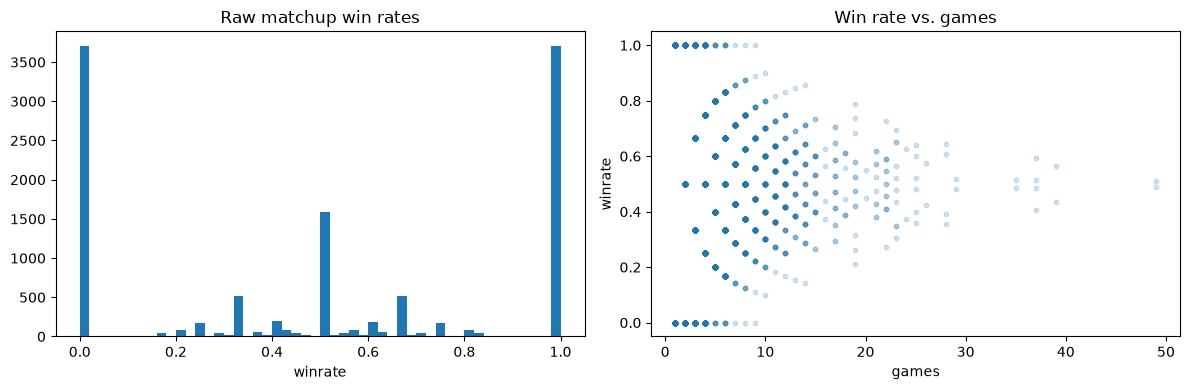

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# raw winrate distribution — note the spikes at 0.0, 0.5, 1.0
ax[0].hist(matchups["winrate"].astype(float), bins=50)
ax[0].set_title("Raw matchup win rates")
ax[0].set_xlabel("winrate")

# winrate vs sample size — the funnel of doom
ax[1].scatter(matchups["games"], matchups["winrate"].astype(float), alpha=0.2, s=10)
ax[1].set_title("Win rate vs. games")
ax[1].set_xlabel("games"); ax[1].set_ylabel("winrate")

plt.tight_layout(); plt.show()

In [3]:
# baseline lookup: champion + lane -> overall winrate
base = baselines.set_index(["champion", "lane"])["winrate"].astype(float)

m = matchups.copy()
m["games"] = m["games"].astype(int)
m["wins"] = m["wins"].astype(int)
m["raw_winrate"] = m["wins"] / m["games"]
m["baseline"] = m.apply(lambda r: base.get((r["champion"], r["lane"]), 0.5), axis=1)

k = 20.0   # prior strength: the prior is "worth" ~20 games. We'll estimate this properly next.
m["alpha"] = k * m["baseline"]
m["beta"]  = k * (1 - m["baseline"])
m["shrunk_winrate"] = (m["wins"] + m["alpha"]) / (m["games"] + m["alpha"] + m["beta"])

m[["champion", "opponent", "lane", "games", "raw_winrate", "baseline", "shrunk_winrate"]].head(15)

,champion,opponent,lane,games,raw_winrate,baseline,shrunk_winrate
0,Senna,Lux,UTILITY,20,0.550000,0.509,0.529500
1,Nasus,Mordekaiser,TOP,4,0.250000,0.451,0.417500
2,Nautilus,Blitzcrank,UTILITY,8,0.500000,0.478,0.484286
3,Sion,Mordekaiser,TOP,12,0.500000,0.485,0.490625
4,KSante,Kled,TOP,1,1.000000,0.479,0.503810
5,MissFortune,Jinx,BOTTOM,23,0.434783,0.505,0.467442
6,Smolder,Senna,BOTTOM,11,0.272727,0.513,0.427742
7,Jhin,Yunara,BOTTOM,14,0.428571,0.480,0.458824
8,MissFortune,Caitlyn,BOTTOM,37,0.513514,0.505,0.510526
9,Kassadin,Yone,MIDDLE,5,1.000000,0.463,0.570400


In [4]:
# the sparse cells: watch raw extremes get pulled to baseline
m[m["games"] <= 2].sort_values("games")[
    ["champion", "opponent", "lane", "games", "wins", "raw_winrate", "baseline", "shrunk_winrate"]
].head(15)

,champion,opponent,lane,games,wins,raw_winrate,baseline,shrunk_winrate
11652,Xayah,Yunara,BOTTOM,1,0,0.0,0.538,0.512381
11650,Nautilus,Jax,TOP,1,0,0.0,0.000,0.000000
57,Teemo,Zaahen,TOP,1,1,1.0,0.505,0.528571
54,Kennen,Cassiopeia,TOP,1,0,0.0,0.621,0.591429
53,Shen,Syndra,MIDDLE,1,1,1.0,0.500,0.523810
52,Heimerdinger,Hwei,TOP,1,1,1.0,0.524,0.546667
46,Smolder,Zaahen,TOP,1,1,1.0,0.545,0.566667
45,Teemo,MonkeyKing,TOP,1,1,1.0,0.505,0.528571
40,Orianna,Diana,MIDDLE,1,0,0.0,0.520,0.495238
38,Brand,Vladimir,MIDDLE,1,1,1.0,0.528,0.550476


In [5]:
# the dense cells: shrinkage barely touches them
m[m["games"] >= 40].sort_values("games", ascending=False)[
    ["champion", "opponent", "lane", "games", "wins", "raw_winrate", "baseline", "shrunk_winrate"]
].head(10)

,champion,opponent,lane,games,wins,raw_winrate,baseline,shrunk_winrate
234,Ezreal,Caitlyn,BOTTOM,49,25,0.510204,0.445,0.491304
7598,Caitlyn,Ezreal,BOTTOM,49,24,0.489796,0.506,0.494493


In [6]:
# Fit the prior on well-sampled matchups only, so we're measuring real
# spread rather than the noise of tiny samples.
well = m[m["games"] >= 20]
rates = well["wins"] / well["games"]

mean = rates.mean()
var = rates.var()

# Method of moments for a Beta(alpha, beta):
# solve for the concentration k = alpha + beta from mean and variance.
k_hat = mean * (1 - mean) / var - 1

print(f"well-sampled matchups: {len(well)}")
print(f"mean winrate: {mean:.4f}   variance: {var:.5f}")
print(f"estimated prior strength k_hat: {k_hat:.1f}")

well-sampled matchups: 62
mean winrate: 0.5000   variance: 0.01012
estimated prior strength k_hat: 23.7


In [7]:
k = float(k_hat)
m["alpha"] = k * m["baseline"]
m["beta"]  = k * (1 - m["baseline"])
m["shrunk_winrate"] = (m["wins"] + m["alpha"]) / (m["games"] + m["alpha"] + m["beta"])

print(f"Using empirically estimated k = {k:.1f}")
m[m["games"] <= 2][["champion","opponent","games","wins","raw_winrate","baseline","shrunk_winrate"]].head(8)

Using empirically estimated k = 23.7


,champion,opponent,games,wins,raw_winrate,baseline,shrunk_winrate
4,KSante,Kled,1,1,1.0,0.479,0.500099
12,Lux,Cassiopeia,1,0,0.0,0.500,0.479752
16,Zoe,Kindred,1,1,1.0,0.418,0.441569
17,Gangplank,Aatrox,2,1,0.5,0.509,0.508299
19,Warwick,MonkeyKing,2,1,0.5,0.552,0.547952
22,Olaf,Riven,1,0,0.0,0.333,0.319515
23,Tristana,Mordekaiser,1,0,0.0,0.250,0.239876
27,Velkoz,Ekko,1,0,0.0,0.541,0.519091


In [8]:
from sklearn.model_selection import train_test_split

# Expand each matchup's (wins, games) back into individual 1/0 outcomes.
records = []
for _, r in m.iterrows():
    key = (r["champion"], r["opponent"], r["lane"])
    records += [(key, 1)] * int(r["wins"])
    records += [(key, 0)] * int(r["games"] - r["wins"])

games_df = pd.DataFrame(records, columns=["matchup", "outcome"])
train, test = train_test_split(games_df, test_size=0.5, random_state=42)
print(f"train games: {len(train)}, test games: {len(test)}")

train games: 15496, test games: 15496


In [9]:
# Train-half aggregates per matchup
tr = train.groupby("matchup")["outcome"].agg(["sum", "count"]).rename(
    columns={"sum": "wins", "count": "games"})

# Baseline per matchup (champion+lane overall), reused from before
def baseline_for(matchup):
    champ, opp, lane = matchup
    return base.get((champ, lane), 0.5)

tr["baseline"] = [baseline_for(mk) for mk in tr.index]
tr["raw"] = tr["wins"] / tr["games"]
tr["shrunk"] = (tr["wins"] + k * tr["baseline"]) / (tr["games"] + k)

# Global fallback for matchups unseen in train (predict overall mean)
global_mean = train["outcome"].mean()

In [10]:
import numpy as np

def logloss(y, p, eps=1e-9):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

# Attach train-derived predictions to each test game
test = test.copy()
test["raw_pred"]    = test["matchup"].map(tr["raw"]).fillna(global_mean)
test["shrunk_pred"] = test["matchup"].map(tr["shrunk"]).fillna(global_mean)

y = test["outcome"].values
print(f"Raw    win-rate log-loss: {logloss(y, test['raw_pred'].values):.4f}")
print(f"Shrunk win-rate log-loss: {logloss(y, test['shrunk_pred'].values):.4f}")

Raw    win-rate log-loss: 3.6777
Shrunk win-rate log-loss: 0.6928


In [11]:
test = test.copy()
test["train_games"] = test["matchup"].map(tr["games"]).fillna(0)

for lo, hi, label in [(0, 3, "sparse (≤3 train games)"),
                      (4, 15, "medium (4–15)"),
                      (16, 10_000, "dense (16+)")]:
    mask = (test["train_games"] >= lo) & (test["train_games"] <= hi)
    if mask.sum() == 0:
        continue
    yy = test.loc[mask, "outcome"].values
    raw_ll = logloss(yy, test.loc[mask, "raw_pred"].values)
    shr_ll = logloss(yy, test.loc[mask, "shrunk_pred"].values)
    print(f"{label:24s}  n={mask.sum():6d}  raw={raw_ll:.3f}  shrunk={shr_ll:.3f}")

sparse (≤3 train games)   n= 11359  raw=4.528  shrunk=0.691
medium (4–15)             n=  3956  raw=1.370  shrunk=0.697
dense (16+)               n=   181  raw=0.728  shrunk=0.704


In [12]:
import boto3, json, os
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv())

MY_PUUID = "DhjPx7bSiVYKSyPeLi-BS6jZeyri3beYBHtGhCoM_ItlASVre9N7JLTZRX7oBhI2CGYUysx99MBKhg"  

# Reuse the Athena helper — count matches where you're a participant
from common.athena import run_query
rows = run_query(f"""
SELECT count(*) AS my_games
FROM raw_matches
CROSS JOIN UNNEST(info.participants) AS t(p)
WHERE p.puuid = '{MY_PUUID}'
""")
print(rows)

[{'my_games': '524'}]


In [13]:
MY_PUUID = "DhjPx7bSiVYKSyPeLi-BS6jZeyri3beYBHtGhCoM_ItlASVre9N7JLTZRX7oBhI2CGYUysx99MBKhg"

from common.athena import run_query
import pandas as pd

personal = pd.DataFrame(run_query(f"""
WITH me AS (
  SELECT metadata.matchId AS match_id,
         p.championName AS champion,
         p.teamId AS team_id,
         p.teamPosition AS lane,
         p.win AS win
  FROM raw_matches
  CROSS JOIN UNNEST(info.participants) AS t(p)
  WHERE p.puuid = '{MY_PUUID}' AND p.teamPosition <> ''
),
opp AS (
  SELECT metadata.matchId AS match_id,
         p.championName AS champion,
         p.teamId AS team_id,
         p.teamPosition AS lane
  FROM raw_matches
  CROSS JOIN UNNEST(info.participants) AS t(p)
  WHERE p.teamPosition <> ''
)
SELECT
  me.champion AS champion,
  opp.champion AS opponent,
  me.lane AS lane,
  count(*) AS games,
  sum(CASE WHEN me.win THEN 1 ELSE 0 END) AS wins
FROM me
JOIN opp
  ON me.match_id = opp.match_id
 AND me.lane = opp.lane
 AND me.team_id <> opp.team_id
GROUP BY me.champion, opp.champion, me.lane
ORDER BY games DESC
"""))

for c in ["games", "wins"]:
    personal[c] = personal[c].astype(int)
personal["raw_winrate"] = personal["wins"] / personal["games"]
print(f"{len(personal)} distinct personal matchups, {personal['games'].sum()} total games")
personal.head(20)

266 distinct personal matchups, 524 total games


,champion,opponent,lane,games,wins,raw_winrate
0,Yasuo,Ahri,MIDDLE,17,13,0.764706
1,Yasuo,Malzahar,MIDDLE,12,7,0.583333
2,Yasuo,Yone,MIDDLE,10,7,0.700000
3,Yasuo,Akali,MIDDLE,9,5,0.555556
4,Yone,Akali,MIDDLE,9,2,0.222222
5,Yasuo,Sylas,MIDDLE,8,5,0.625000
6,Yone,Ahri,MIDDLE,8,3,0.375000
7,Yasuo,AurelionSol,MIDDLE,7,3,0.428571
8,Yasuo,Ekko,MIDDLE,7,3,0.428571
9,Yone,Yasuo,MIDDLE,6,1,0.166667


In [14]:
# Shrink your personal record toward the population matchup rate 

# Population matchup win rate = the prior for each personal cell
pop = matchups.copy()
pop["games"] = pop["games"].astype(int)
pop["wins"] = pop["wins"].astype(int)
pop["pop_winrate"] = pop["wins"] / pop["games"]
pop_lookup = pop.set_index(["champion", "opponent", "lane"])["pop_winrate"]

# champion-lane baseline = fallback prior when the population matchup cell is missing
base_lookup = baselines.set_index(["champion", "lane"])["winrate"].astype(float)

def prior_for(row):
    # most-specific prior available: population matchup rate, else champion baseline, else 0.5
    p = pop_lookup.get((row["champion"], row["opponent"], row["lane"]))
    if p is not None:
        return p
    b = base_lookup.get((row["champion"], row["lane"]))
    return b if b is not None else 0.5

personal["population_winrate"] = personal.apply(prior_for, axis=1)

k = 20.0  # prior strength; swap in your empirical k_hat if you kept it
personal["shrunk_winrate"] = (
    (personal["wins"] + k * personal["population_winrate"]) /
    (personal["games"] + k)
)

# how much you beat (or trail) the baseline, honestly weighted by your sample size
personal["edge"] = personal["shrunk_winrate"] - personal["population_winrate"]

personal[[
    "champion", "opponent", "lane", "games", "wins",
    "raw_winrate", "population_winrate", "shrunk_winrate", "edge"
]].head(20)

,champion,opponent,lane,games,wins,raw_winrate,population_winrate,shrunk_winrate,edge
0,Yasuo,Ahri,MIDDLE,17,13,0.764706,0.538462,0.642412,0.103950
1,Yasuo,Malzahar,MIDDLE,12,7,0.583333,0.300000,0.406250,0.106250
2,Yasuo,Yone,MIDDLE,10,7,0.700000,0.357143,0.471429,0.114286
3,Yasuo,Akali,MIDDLE,9,5,0.555556,0.416667,0.459770,0.043103
4,Yone,Akali,MIDDLE,9,2,0.222222,0.571429,0.463054,-0.108374
5,Yasuo,Sylas,MIDDLE,8,5,0.625000,0.750000,0.714286,-0.035714
6,Yone,Ahri,MIDDLE,8,3,0.375000,0.454545,0.431818,-0.022727
7,Yasuo,AurelionSol,MIDDLE,7,3,0.428571,0.000000,0.111111,0.111111
8,Yasuo,Ekko,MIDDLE,7,3,0.428571,0.500000,0.481481,-0.018519
9,Yone,Yasuo,MIDDLE,6,1,0.166667,0.642857,0.532967,-0.109890


In [15]:
# Use the SHRUNK population matchup rate as the prior (hierarchical: priors shrink too)
pop_shrunk_lookup = m.set_index(["champion", "opponent", "lane"])["shrunk_winrate"]
base_lookup = baselines.set_index(["champion", "lane"])["winrate"].astype(float)

def prior_for(row):
    p = pop_shrunk_lookup.get((row["champion"], row["opponent"], row["lane"]))
    if p is not None:
        return float(p)
    b = base_lookup.get((row["champion"], row["lane"]))
    return float(b) if b is not None else 0.5

personal["population_winrate"] = personal.apply(prior_for, axis=1)

k = 20.0
personal["shrunk_winrate"] = (
    (personal["wins"] + k * personal["population_winrate"]) /
    (personal["games"] + k)
)
personal["edge"] = personal["shrunk_winrate"] - personal["population_winrate"]

personal[["champion","opponent","lane","games","wins",
          "raw_winrate","population_winrate","shrunk_winrate","edge"]].head(20)

,champion,opponent,lane,games,wins,raw_winrate,population_winrate,shrunk_winrate,edge
0,Yasuo,Ahri,MIDDLE,17,13,0.764706,0.498775,0.620960,0.122184
1,Yasuo,Malzahar,MIDDLE,12,7,0.583333,0.424467,0.484042,0.059575
2,Yasuo,Yone,MIDDLE,10,7,0.700000,0.432483,0.521655,0.089172
3,Yasuo,Akali,MIDDLE,9,5,0.555556,0.456716,0.487390,0.030674
4,Yone,Akali,MIDDLE,9,2,0.222222,0.487729,0.405330,-0.082399
5,Yasuo,Sylas,MIDDLE,8,5,0.625000,0.545911,0.568508,0.022597
6,Yone,Ahri,MIDDLE,8,3,0.375000,0.460319,0.435942,-0.024377
7,Yasuo,AurelionSol,MIDDLE,7,3,0.428571,0.439870,0.436940,-0.002929
8,Yasuo,Ekko,MIDDLE,7,3,0.428571,0.478790,0.465771,-0.013020
9,Yone,Yasuo,MIDDLE,6,1,0.166667,0.529802,0.446002,-0.083801


In [16]:
from common.ddragon import get_latest_version, get_items, build_item_id_map
from common.athena import run_query
import pandas as pd

version = get_latest_version()
item_names = build_item_id_map(get_items(version))

yasuo_items = pd.DataFrame(run_query("""
WITH players AS (
  SELECT p.championName AS champion, p.win AS win,
    array[p.item0,p.item1,p.item2,p.item3,p.item4,p.item5] AS items
  FROM raw_matches CROSS JOIN UNNEST(info.participants) AS t(p)
  WHERE p.championName = 'Yasuo' AND p.teamPosition = 'MIDDLE'
)
SELECT item_id, count(*) AS games,
  sum(CASE WHEN win THEN 1 ELSE 0 END) AS wins,
  round(avg(CASE WHEN win THEN 1.0 ELSE 0.0 END), 3) AS winrate
FROM players CROSS JOIN UNNEST(items) AS u(item_id)
WHERE item_id <> 0
GROUP BY item_id ORDER BY games DESC
"""))

yasuo_items["games"] = yasuo_items["games"].astype(int)
yasuo_items["wins"] = yasuo_items["wins"].astype(int)
yasuo_items["item"] = yasuo_items["item_id"].astype(int).map(item_names)
yasuo_items[["item", "games", "wins", "winrate"]].head(25)

,item,games,wins,winrate
0,Immortal Shieldbow,333,191,0.574
1,Gunmetal Greaves,310,164,0.529
2,Blade of The Ruined King,309,164,0.531
3,Infinity Edge,228,136,0.596
4,Kraken Slayer,115,60,0.522
5,Doran's Bow,112,53,0.473
6,Mortal Reminder,90,47,0.522
7,Berserker's Greaves,89,52,0.584
8,Doran's Shield,87,54,0.621
9,Death's Dance,87,44,0.506


In [17]:
from common.ddragon import get_latest_version, get_items

version = get_latest_version()
items_raw = get_items(version)

# A "completed" item builds into nothing further (no 'into' list),
# is purchasable, and costs a meaningful amount (drops consumables/trinkets).
completed_ids = {
    int(item_id)
    for item_id, meta in items_raw.items()
    if not meta.get("into")                          # nothing builds from it
    and meta.get("gold", {}).get("total", 0) >= 2000 # real finished-item cost
    and meta.get("gold", {}).get("purchasable", True)
}

print(f"{len(completed_ids)} completed items in patch {version}")

# Filtering Yasuo table to just completed items
yasuo_completed = yasuo_items[yasuo_items["item_id"].astype(int).isin(completed_ids)]
yasuo_completed[["item", "games", "wins", "winrate"]].head(20)

388 completed items in patch 16.15.1


,item,games,wins,winrate
0,Immortal Shieldbow,333,191,0.574
2,Blade of The Ruined King,309,164,0.531
3,Infinity Edge,228,136,0.596
4,Kraken Slayer,115,60,0.522
6,Mortal Reminder,90,47,0.522
9,Death's Dance,87,44,0.506
11,Phantom Dancer,86,51,0.593
16,Lord Dominik's Regards,61,36,0.59
17,Stridebreaker,57,36,0.632
21,Wit's End,34,18,0.529


In [18]:
import pandas as pd
with psycopg.connect(url) as conn:
    items = pd.read_sql("SELECT * FROM item_stats", conn)

items["games"] = items["games"].astype(int)
items["wins"] = items["wins"].astype(int)
items["raw_winrate"] = items["wins"] / items["games"]

# prior = champion's overall win rate (avg across lanes from baselines)
champ_overall = baselines.groupby("champion").apply(
    lambda g: (g["wins"].astype(int).sum() / g["games"].astype(int).sum())
)
items["prior"] = items["champion"].map(champ_overall).fillna(0.5)

k = 20.0
items["shrunk_winrate"] = (items["wins"] + k * items["prior"]) / (items["games"] + k)
items["edge"] = items["shrunk_winrate"] - items["prior"]

# your champion, shrunk — watch the noisy tail collapse
items[items["champion"] == "Yasuo"].sort_values("games", ascending=False)[
    ["item_name","games","wins","raw_winrate","prior","shrunk_winrate","edge"]
].head(20)

C:\Users\lyons\AppData\Local\Temp\ipykernel_18100\4137267180.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  items = pd.read_sql("SELECT * FROM item_stats", conn)


,item_name,games,wins,raw_winrate,prior,shrunk_winrate,edge
4155,Immortal Shieldbow,449,249,0.554566,0.47343,0.551106,0.077676
2096,Blade of The Ruined King,420,213,0.507143,0.47343,0.505610,0.032181
3207,Infinity Edge,301,178,0.591362,0.47343,0.584014,0.110584
2398,Kraken Slayer,164,84,0.512195,0.47343,0.507982,0.034552
568,Mortal Reminder,119,58,0.487395,0.47343,0.485386,0.011956
3071,Death's Dance,114,62,0.543860,0.47343,0.533348,0.059918
3896,Phantom Dancer,95,53,0.557895,0.47343,0.543205,0.069775
835,Lord Dominik's Regards,83,48,0.578313,0.47343,0.557948,0.084518
2406,Stridebreaker,60,36,0.600000,0.47343,0.568357,0.094928
24,Wit's End,39,20,0.512821,0.47343,0.499468,0.026038
